# ReturnGuard — Model optimization & readable workflow
MGSC 661 | ASOS GraphReturns | revised from ReturnGuard_PoC.ipynb

**Goal:** improve out-of-customer validation AUC without using contemporaneous outcome aggregates; preserve RQ1 (prediction), RQ2 (associations), and RQ3 (intervention economics).

Original saved results: LightGBM CV AUC 0.6815; later-period AUC 0.6813, average precision 0.6961. These are historical results, not results of this revision. The later period has already been inspected in the PoC, so it is a reused benchmark, not a pristine final test. A new future period is needed for independent confirmation.

**Run:** download the six pickle files from https://osf.io/c793h/ into `data/` beside this notebook (or directly beside it). Only load trusted pickle files. Install dependencies with `%pip install pandas numpy matplotlib scikit-learn lightgbm statsmodels` if needed. Run all cells in order. Full five-fold comparisons can take substantial time on a laptop. The six source files are required to reproduce the results. Saved outputs, if present, are not evidence of a fresh run.

**Assumptions:** period-average price and discount are retained for PoC comparability, but must be proven available at checkout. Product/supplier IDs are experimental, subject to availability and stability checks. No same-period returns, sales aggregates or return reasons enter the predictive features. Prior-period outcomes are used for association only; outcome maturity is unknown.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss,
    brier_score_loss, precision_score, recall_score, accuracy_score,
    RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.calibration import CalibrationDisplay

DATA = Path("data") if Path("data/event_table_training.p").exists() else Path(".")
SEED = 0
N_FOLDS = 5
N_JOBS = 4
TARGET = "isReturned"
GROUP = "hash(customerId)"
VARIANT = "hash(variantID)"
ID_FEATURES = ["hash(productID)", "hash(supplierRef)", VARIANT]
MIN_ID_COUNT = 30
RUN_ASSOCIATIONS = True
RUN_LEAKAGE_DEMO = False  # diagnostic only; never used for selection
RUN_EXTRA_MODELS = True
pd.set_option("display.max_columns", 25)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.2})

## 2. Load tables and audit joins
Keep original inner-join cohort for comparable model metrics. Report return prevalence before and after joining; exact duplicates are ambiguous without transaction timestamps. Validate join cardinality rather than silently multiplying events.

In [2]:
def load_period(period):
    paths = [DATA / f"{table}_{period}.p" for table in
             ("event_table", "customer_nodes", "product_nodes")]
    missing = [str(path) for path in paths if not path.exists()]
    if missing:
        raise FileNotFoundError("Missing ASOS files: " + ", ".join(missing))
    events, customers, products = [pd.read_pickle(path) for path in paths]
    duplicate_count = int(events.duplicated().sum())
    raw_count = len(events)
    raw_rate = events[TARGET].mean()
    events = events.drop_duplicates().copy()
    customers = customers.loc[:, ~customers.columns.duplicated()]
    products = products.loc[:, ~products.columns.duplicated()]
    assert events[TARGET].isin([0, 1]).all(), "Unexpected target values"
    print(f"{period}: {raw_count:,} raw; return rate {raw_rate:.2%}; "
          f"{duplicate_count:,} exact duplicates removed")
    return events, customers, products


def merge_period(events, customers, products):
    customer_columns = [GROUP, "yearOfBirth", "isMale", "premier", "shippingCountry",
                        "salesPerCustomer", "customerReturnRate"]
    product_columns = [VARIANT, "productType", "brandDesc", "avgGbpPrice",
                       "avgDiscountValue", "salesPerProduct", "productReturnRate"]
    customer_columns += [c for c in customers if c.startswith("Country_")]
    product_columns += [c for c in products if c.startswith(("Brand_", "productType_"))]
    product_columns += [c for c in ID_FEATURES if c in products and c != VARIANT]
    for frame in (customers, products):
        for col in frame.columns:
            if col.startswith(("Country_", "Brand_", "productType_")):
                frame[col] = pd.to_numeric(frame[col], downcast="integer")
    return (events.merge(customers[customer_columns], on=GROUP, how="inner", validate="many_to_one")
                  .merge(products[product_columns], on=VARIANT, how="inner", validate="many_to_one"))


ev_tr, cu_tr, pr_tr = load_period("training")
df_tr = merge_period(ev_tr, cu_tr, pr_tr)
print("All earlier customer nodes have a return:", (cu_tr.returnsPerCustomer >= 1).all())
del cu_tr, pr_tr
gc.collect()
ev_te, cu_te, pr_te = load_period("testing")
df_te = merge_period(ev_te, cu_te, pr_te)
del cu_te, pr_te
gc.collect()

training: 1,369,133 raw; return rate 55.31%; 6,551 exact duplicates removed
All earlier customer nodes have a return: True
testing: 1,460,366 raw; return rate 54.46%; 7,223 exact duplicates removed


0

In [3]:
def describe_labels(frame, period, stage):
    counts = frame[TARGET].value_counts()
    return {"period": period, "stage": stage, "rows": len(frame),
            "positive": counts.get(1, 0), "negative": counts.get(0, 0),
            "return_rate": frame[TARGET].mean()}

label_audit = pd.DataFrame([
    describe_labels(frame, period, stage)
    for period, raw, joined in [("earlier", ev_tr, df_tr), ("later", ev_te, df_te)]
    for stage, frame in [("deduplicated events", raw), ("inner join", joined)]
])
display(label_audit.round(4))
for period, raw, joined in [("earlier", ev_tr, df_tr), ("later", ev_te, df_te)]:
    print(period, "join coverage by class:",
          (joined[TARGET].value_counts() / raw[TARGET].value_counts()).round(4).to_dict())

,period,stage,rows,positive,negative,return_rate
0,earlier,deduplicated events,1362582,755220,607362,0.5543
1,earlier,inner join,844405,463121,381284,0.5485
2,later,deduplicated events,1453143,793258,659885,0.5459
3,later,inner join,955792,512199,443593,0.5359


earlier join coverage by class: {1: 0.6132, 0: 0.6278}
later join coverage by class: {1: 0.6457, 0: 0.6722}


## 3. Feature definitions and exploratory analysis
Define the original 35-feature allowlist from training columns only. Price and discount are provisional checkout proxies. Do not use customer ID as a predictor. Raw IDs for products and suppliers are tested separately with rare/unseen levels mapped to missing using only the fitting fold.

Original predictor count: 35


,size,mean
avgGbpPrice,,
"(1.729, 11.28]",169010,0.393178
"(11.28, 17.07]",168787,0.519228
"(17.07, 23.9]",168914,0.567750
"(23.9, 33.91]",168870,0.606650
"(33.91, 420.0]",168824,0.655624


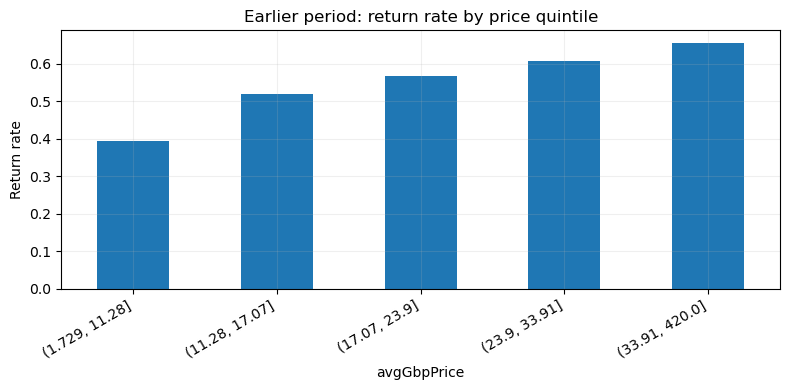

In [4]:
numeric_features = ["yearOfBirth", "avgGbpPrice", "avgDiscountValue"]
SAFE = ["yearOfBirth", "isMale", "premier", "avgGbpPrice", "avgDiscountValue"]
SAFE += [c for c in df_tr if c.startswith(("Country_", "Brand_", "productType_"))]
binary_features = [c for c in SAFE if c not in numeric_features]
assert set(SAFE).issubset(df_te.columns), "Feature schema changed"
assert not any("return" in c.lower() or "sales" in c.lower() for c in SAFE)
print("Original predictor count:", len(SAFE))

price_band = pd.qcut(df_tr.avgGbpPrice, 5, duplicates="drop")
price_summary = df_tr.groupby(price_band, observed=True)[TARGET].agg(["size", "mean"])
display(price_summary)
price_summary["mean"].plot.bar(title="Earlier period: return rate by price quintile", ylabel="Return rate")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 4. Candidate models
The baseline matches the original hyperparameters. Compare a balanced-weight model, two larger regularized tree configurations, and an experimental product-ID model. A demographic ablation and a price/discount ablation test sensitivity to fairness and checkout availability. Select exclusively on earlier-period grouped CV. Class weighting is an experiment, not a default fix.

In [5]:
BASE_LGBM = dict(n_estimators=300, learning_rate=0.05, num_leaves=31,
    min_child_samples=100, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, reg_lambda=1.0)
TUNED_LGBM = dict(n_estimators=600, learning_rate=0.035, num_leaves=63,
    min_child_samples=150, subsample=0.85, subsample_freq=1,
    colsample_bytree=0.85, reg_lambda=3.0)

candidates = {
    "Logistic baseline": dict(kind="lr", features=SAFE),
    "LightGBM baseline": dict(kind="lgbm", features=SAFE, params=BASE_LGBM),
}
if RUN_EXTRA_MODELS:
    candidates.update({
        "LightGBM balanced": dict(kind="lgbm", features=SAFE,
            params={**BASE_LGBM, "class_weight": "balanced"}),
        "LightGBM tuned A": dict(kind="lgbm", features=SAFE, params=TUNED_LGBM),
        "LightGBM tuned B": dict(kind="lgbm", features=SAFE,
            params={**TUNED_LGBM, "num_leaves": 127, "min_child_samples": 300,
                    "reg_lambda": 8.0}),
        "LightGBM product IDs": dict(kind="lgbm", features=SAFE + ID_FEATURES,
            params={**TUNED_LGBM, "cat_smooth": 30, "cat_l2": 20}, ids=ID_FEATURES),
        "LightGBM no demographics": dict(kind="lgbm",
            features=[c for c in SAFE if c not in ["yearOfBirth", "isMale"]], params=TUNED_LGBM),
        "LightGBM no price proxies": dict(kind="lgbm",
            features=[c for c in SAFE if c not in ["avgGbpPrice", "avgDiscountValue"]], params=TUNED_LGBM),
    })


def prepare_features(fit_rows, score_rows, spec):
    """Fit ID vocabulary on fit rows only; unseen IDs are missing."""
    columns = spec["features"]
    ids = spec.get("ids", [])
    numeric = [c for c in columns if c not in ids]
    X_fit = fit_rows[numeric].apply(pd.to_numeric, errors="coerce").astype("float32")
    X_score = score_rows[numeric].apply(pd.to_numeric, errors="coerce").astype("float32")
    X_fit = X_fit.replace([np.inf, -np.inf], np.nan)
    X_score = X_score.replace([np.inf, -np.inf], np.nan)
    for column in ids:
        counts = fit_rows[column].value_counts()
        levels = counts[counts >= MIN_ID_COUNT].index
        X_fit[column] = pd.Categorical(fit_rows[column], categories=levels)
        X_score[column] = pd.Categorical(score_rows[column], categories=levels)
    return X_fit[columns], X_score[columns]


def make_model(spec):
    if spec["kind"] == "lr":
        numeric = [c for c in numeric_features if c in spec["features"]]
        other = [c for c in spec["features"] if c not in numeric]
        preprocess = ColumnTransformer([
            ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")),
                                   ("scale", StandardScaler())]), numeric),
            ("binary", SimpleImputer(strategy="constant", fill_value=0), other),
        ])
        return Pipeline([("preprocess", preprocess),
                         ("model", LogisticRegression(max_iter=1000, random_state=SEED))])
    return LGBMClassifier(**spec["params"], n_jobs=N_JOBS, random_state=SEED, verbosity=-1)


def evaluate(y, probability, threshold=0.5):
    predicted = probability >= threshold
    return {"ROC AUC": roc_auc_score(y, probability),
            "Average precision": average_precision_score(y, probability),
            "Log loss": log_loss(y, probability, labels=[0, 1]),
            "Brier score": brier_score_loss(y, probability),
            "Precision": precision_score(y, predicted, zero_division=0),
            "Recall": recall_score(y, predicted, zero_division=0),
            "Accuracy": accuracy_score(y, predicted), "Flagged rate": predicted.mean()}

## 5. Customer-grouped cross-validation
All candidates use the same folds. Fit preprocessing and ID vocabularies inside each fold. Out-of-fold predictions are retained for calibration. The selected CV result can be optimistic after model search; later-period results are a reused benchmark.

Completed: Logistic baseline
Completed: LightGBM baseline
Completed: LightGBM balanced
Completed: LightGBM tuned A
Completed: LightGBM tuned B
Completed: LightGBM product IDs
Completed: LightGBM no demographics
Completed: LightGBM no price proxies


,mean_auc,sd_auc,mean_ap,mean_brier,mean_log_loss,mean_precision,mean_recall,mean_flagged,delta_vs_baseline
model,,,,,,,,,
LightGBM product IDs,0.6879,0.0015,0.7131,0.2206,0.6307,0.6550,0.7311,0.6122,0.0064
LightGBM tuned B,0.6857,0.0018,0.7119,0.2214,0.6326,0.6518,0.7352,0.6186,0.0042
LightGBM tuned A,0.6842,0.0018,0.7110,0.2218,0.6337,0.6509,0.7341,0.6185,0.0028
LightGBM no demographics,0.6825,0.0017,0.7093,0.2222,0.6345,0.6498,0.7340,0.6196,0.0010
LightGBM baseline,0.6815,0.0016,0.7088,0.2227,0.6357,0.6506,0.7290,0.6146,0.0000
LightGBM balanced,0.6815,0.0018,0.7088,0.2247,0.6399,0.6742,0.6346,0.5162,-0.0000
Logistic baseline,0.6643,0.0012,0.6932,0.2281,0.6479,0.6551,0.6646,0.5564,-0.0172
LightGBM no price proxies,0.6575,0.0018,0.6908,0.2292,0.6499,0.6476,0.6771,0.5735,-0.0240


Selected by CV AUC: LightGBM product IDs


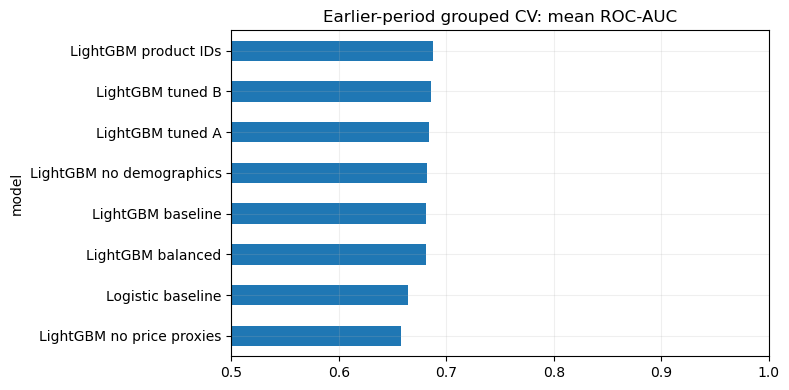

In [6]:
train_model = df_tr.dropna(subset=[TARGET, GROUP]).reset_index(drop=True)
test_model = df_te.dropna(subset=[TARGET, GROUP]).reset_index(drop=True)
y_train = train_model[TARGET].astype(int)
y_test = test_model[TARGET].astype(int)
folds = list(GroupKFold(n_splits=N_FOLDS).split(train_model, y_train, train_model[GROUP]))
for fit_idx, val_idx in folds:
    assert not set(train_model.iloc[fit_idx][GROUP]).intersection(train_model.iloc[val_idx][GROUP])

cv_records = []
oof_predictions = {}
for name, spec in candidates.items():
    if not set(spec["features"]).issubset(train_model.columns):
        print("Skipping missing feature candidate:", name)
        continue
    oof = np.full(len(train_model), np.nan)
    for fold, (fit_idx, val_idx) in enumerate(folds, 1):
        X_fit, X_val = prepare_features(train_model.iloc[fit_idx], train_model.iloc[val_idx], spec)
        model = make_model(spec)
        model.fit(X_fit, y_train.iloc[fit_idx])
        probability = model.predict_proba(X_val)[:, 1]
        oof[val_idx] = probability
        cv_records.append({"model": name, "fold": fold,
                           **evaluate(y_train.iloc[val_idx], probability)})
        del X_fit, X_val, model
    assert np.isfinite(oof).all()
    oof_predictions[name] = oof
    print("Completed:", name)

cv_folds = pd.DataFrame(cv_records)
cv_summary = cv_folds.groupby("model").agg(
    mean_auc=("ROC AUC", "mean"), sd_auc=("ROC AUC", "std"),
    mean_ap=("Average precision", "mean"), mean_brier=("Brier score", "mean"),
    mean_log_loss=("Log loss", "mean"), mean_precision=("Precision", "mean"),
    mean_recall=("Recall", "mean"), mean_flagged=("Flagged rate", "mean"))
cv_summary = cv_summary.sort_values("mean_auc", ascending=False)
cv_summary["delta_vs_baseline"] = cv_summary.mean_auc - cv_summary.loc["LightGBM baseline", "mean_auc"]
display(cv_summary.round(4))
best_model_name = cv_summary.index[0]
print("Selected by CV AUC:", best_model_name)
cv_summary.mean_auc.sort_values().plot.barh(title="Earlier-period grouped CV: mean ROC-AUC", xlim=(0.5, 1))
plt.tight_layout()
plt.show()

## 6. Refit, calibrate and evaluate on the later period
Only refit the CV winner and original LightGBM comparator. Platt calibration is fitted on earlier-period out-of-fold scores, not on test labels. A calibrated weighted model is especially important for economic decisions.

In [7]:
def probability_logit(probability):
    p = np.clip(probability, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

final_models = {}
test_probabilities = {}
calibrated_probabilities = {}
calibrators = {}
test_records = []
for name in dict.fromkeys(["LightGBM baseline", best_model_name]):
    spec = candidates[name]
    X_fit, X_test = prepare_features(train_model, test_model, spec)
    model = make_model(spec)
    model.fit(X_fit, y_train)
    probability = model.predict_proba(X_test)[:, 1]
    calibrator = LogisticRegression(C=1e6, max_iter=1000)
    calibrator.fit(probability_logit(oof_predictions[name]), y_train)
    calibrated = calibrator.predict_proba(probability_logit(probability))[:, 1]
    final_models[name] = model
    test_probabilities[name] = probability
    calibrated_probabilities[name] = calibrated
    calibrators[name] = calibrator
    test_records += [{"model": name, "scores": label, **evaluate(y_test, p)}
                     for label, p in [("raw", probability), ("calibrated", calibrated)]]
    del X_fit, X_test

test_summary = pd.DataFrame(test_records)
display(test_summary.round(4))
p_calibrated = calibrated_probabilities[best_model_name]
print("Later-period calibration is cohort-specific; it does not correct selection bias.")

,model,scores,ROC AUC,Average precision,Log loss,Brier score,Precision,Recall,Accuracy,Flagged rate
0,LightGBM baseline,raw,0.6813,0.6961,0.6378,0.2237,0.6382,0.7320,0.6340,0.6146
1,LightGBM baseline,calibrated,0.6813,0.6961,0.6377,0.2237,0.6388,0.7297,0.6341,0.6121
2,LightGBM product IDs,raw,0.6868,0.7004,0.6336,0.2219,0.6393,0.7406,0.6371,0.6208
3,LightGBM product IDs,calibrated,0.6868,0.7004,0.6336,0.2219,0.6383,0.7438,0.6368,0.6245


Later-period calibration is cohort-specific; it does not correct selection bias.


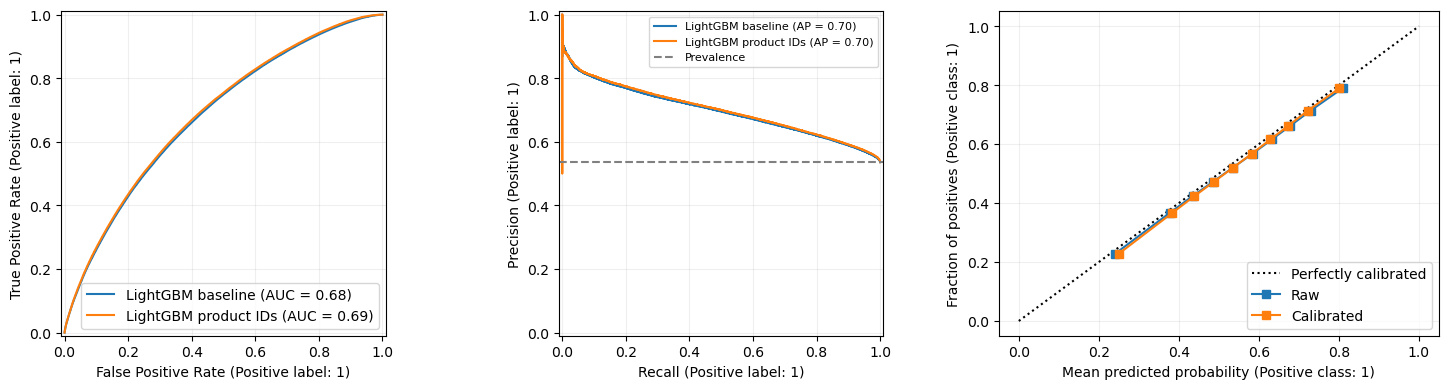

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, p in test_probabilities.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, p, name=name, ax=axes[1])
CalibrationDisplay.from_predictions(y_test, test_probabilities[best_model_name],
    n_bins=10, strategy="quantile", name="Raw", ax=axes[2])
CalibrationDisplay.from_predictions(y_test, p_calibrated,
    n_bins=10, strategy="quantile", name="Calibrated", ax=axes[2])
axes[1].axhline(y_test.mean(), ls="--", color="gray", label="Prevalence")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Risk ranking and subgroup checks
Review risk deciles and the performance of known vs unseen products and each shipping country. These are descriptive checks, not proof of fairness or transportability.

RQ1: observed outcomes by predicted-risk decile (1 = lowest risk):
             purchases actual_return_rate mean_predicted_risk
risk_decile                                                  
1                95580              22.8%               25.0%
2                95579              36.7%               38.3%
3                95579              42.3%               43.8%
4                95579              47.2%               48.7%
5                95579              52.0%               53.5%
6                95579              56.8%               58.3%
7                95579              61.6%               62.9%
8                95579              66.2%               67.3%
9                95579              71.4%               72.3%
10               95580              79.0%               80.1%
Highest-vs-lowest decile return-rate ratio: 3.46x


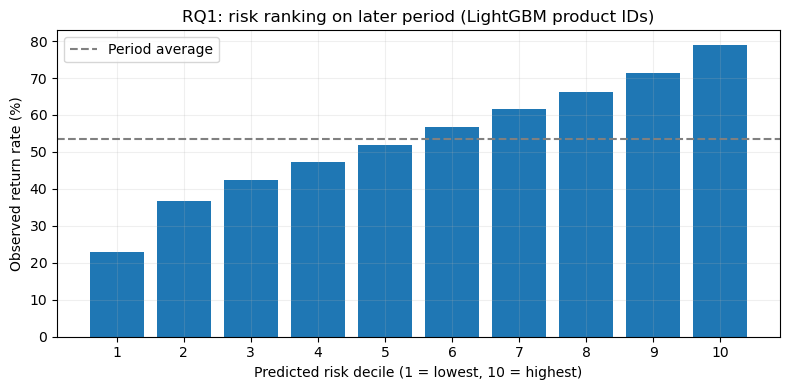

In [9]:
test_scored = test_model[[GROUP, VARIANT, TARGET, "shippingCountry"]].copy()
test_scored["p_return"] = p_calibrated
test_scored["risk_decile"] = pd.qcut(
    test_scored["p_return"].rank(method="first"), 10, labels=range(1, 11)
)
risk_summary = test_scored.groupby("risk_decile", observed=True).agg(
    purchases=(TARGET, "size"),
    actual_return_rate=(TARGET, "mean"),
    mean_predicted_risk=("p_return", "mean"),
)
print("RQ1: observed outcomes by predicted-risk decile (1 = lowest risk):")
print(risk_summary.assign(
    actual_return_rate=lambda table: table.actual_return_rate.map(lambda value: f"{value:.1%}"),
    mean_predicted_risk=lambda table: table.mean_predicted_risk.map(lambda value: f"{value:.1%}"),
).to_string())
low_rate = risk_summary.iloc[0]["actual_return_rate"]
high_rate = risk_summary.iloc[-1]["actual_return_rate"]
print(f"Highest-vs-lowest decile return-rate ratio: {high_rate / low_rate:.2f}x")

plt.figure(figsize=(8, 4))
plt.bar(risk_summary.index.astype(str), risk_summary.actual_return_rate * 100)
plt.axhline(y_test.mean() * 100, linestyle="--", color="grey", label="Period average")
plt.xlabel("Predicted risk decile (1 = lowest, 10 = highest)")
plt.ylabel("Observed return rate (%)")
plt.title(f"RQ1: risk ranking on later period ({best_model_name})")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
def subgroup_metrics(frame, column):
    rows = []
    for value, group in frame.groupby(column, dropna=False, observed=True):
        row = {"group": value, "n": len(group), "return_rate": group[TARGET].mean()}
        if group[TARGET].nunique() == 2:
            row.update(evaluate(group[TARGET], group.p_return.to_numpy()))
        rows.append(row)
    return pd.DataFrame(rows)

test_scored["known_variant"] = test_scored[VARIANT].isin(train_model[VARIANT])
display(subgroup_metrics(test_scored, "known_variant").round(4))
display(subgroup_metrics(test_scored, "shippingCountry").round(4))

,group,n,return_rate,ROC AUC,Average precision,Log loss,Brier score,Precision,Recall,Accuracy,Flagged rate
0,False,260907,0.5464,0.6685,0.6932,0.6433,0.2262,0.6300,0.7602,0.6250,0.6594
1,True,694885,0.5319,0.6932,0.7029,0.6299,0.2203,0.6416,0.7375,0.6413,0.6114


,group,n,return_rate,ROC AUC,Average precision,Log loss,Brier score,Precision,Recall,Accuracy,Flagged rate
0,Country_A,16429,0.4684,0.6533,0.6075,0.6527,0.2307,0.6019,0.5228,0.6145,0.4068
1,Country_B,12547,0.6387,0.6405,0.7477,0.6253,0.2177,0.6662,0.9144,0.6527,0.8766
2,Country_C,10214,0.4782,0.6608,0.6214,0.6510,0.2298,0.5955,0.6112,0.6155,0.4908
3,Country_D,39609,0.4309,0.6396,0.5551,0.6540,0.2312,0.5557,0.4791,0.6105,0.3715
4,Country_E,232581,0.6765,0.6409,0.7778,0.6018,0.2069,0.6910,0.9639,0.6840,0.9437
5,Country_F,18383,0.5865,0.6391,0.6969,0.6481,0.2283,0.6314,0.8447,0.6197,0.7847
6,Country_G,529409,0.4886,0.6794,0.6493,0.6395,0.2249,0.6107,0.6487,0.6263,0.5189
7,Country_H,66833,0.4972,0.6366,0.6180,0.6642,0.2359,0.5863,0.6396,0.5964,0.5424
8,Country_I,29787,0.4875,0.6468,0.6174,0.6580,0.2331,0.5938,0.5959,0.6043,0.4892


## 8. RQ2 — Earlier-period history and adjusted associations
Preserve the PoC association analysis. History is not a prediction feature because within-period timestamps and outcome maturity are unavailable. The following model is descriptive, not causal. Large clustered GLMs may need substantial RAM.

In [11]:
base = ev_tr.isReturned.mean()
cust_hist = ev_tr.groupby("hash(customerId)").isReturned.agg(prior_cust_buys="count", prior_cust_rate="mean").reset_index()
prod_hist = ev_tr.groupby("hash(variantID)").isReturned.agg(prior_prod_buys="count", prior_prod_rate="mean").reset_index()

df = (df_te.merge(cust_hist, on="hash(customerId)", how="left")
           .merge(prod_hist, on="hash(variantID)", how="left"))
for who in ["cust", "prod"]:
    df[f"prior_{who}_seen"] = df[f"prior_{who}_rate"].notna().astype(int)
    df[f"prior_{who}_rate"] = df[f"prior_{who}_rate"].fillna(base)
    df[f"prior_{who}_buys"] = df[f"prior_{who}_buys"].fillna(0)

HIST = ["prior_cust_rate", "prior_cust_buys", "prior_cust_seen",
        "prior_prod_rate", "prior_prod_buys", "prior_prod_seen"]
print(f"Customers seen in the earlier period: {df.prior_cust_seen.mean():.0%} of purchases")
print(f"Products seen in the earlier period:  {df.prior_prod_seen.mean():.0%} of purchases")

Customers seen in the earlier period: 28% of purchases
Products seen in the earlier period:  74% of purchases


RQ2: later-period adjusted associations; includes earlier-period return history.
SE clustered by customer; BH-FDR adjusted. Numeric odds ratios are per 1-SD increase.
Category indicators are relative to an omitted reference; associations are not causal effects.
                    coef  cluster_robust_se   p_value  q_value_FDR  odds_ratio  OR_95_low  OR_95_high  significant_FDR_5pct
prior_prod_buys   -0.119              0.003         0            0       0.888      0.883       0.893                  True
prior_prod_rate    0.257            0.00231         0            0        1.29       1.29         1.3                  True
avgGbpPrice        0.215            0.00296         0            0        1.24       1.23        1.25                  True
prior_cust_rate    0.151            0.00243         0            0        1.16       1.16        1.17                  True
Country_E          0.772             0.0184         0            0        2.17       2.09        2.24                 

avgGbpPrice         261197.847189
Country_E           154020.014892
productType_B        85736.285638
productType_K        46891.793555
productType_I        31809.995492
avgDiscountValue     30814.083634
yearOfBirth          24713.955522
productType_D        18778.422408
Brand_K              16188.433881
Country_G            11810.433090
productType_H         9256.299305
productType_J         9152.374638
isMale                8913.653713
productType_E         7934.531603
Country_D             7774.540060
Name: gain, dtype: float64

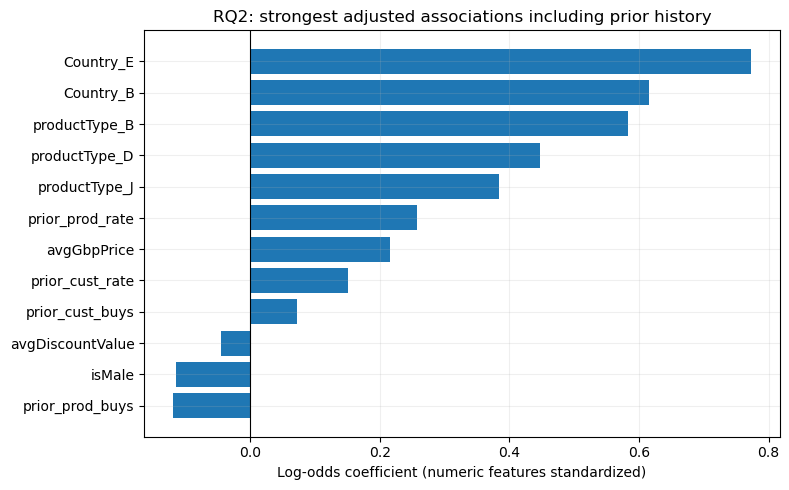

In [12]:
if RUN_ASSOCIATIONS:
    from statsmodels.stats.multitest import multipletests

    inference_features = SAFE + HIST
    for family_prefix in ("Country_", "Brand_", "productType_"):
        family_columns = sorted(c for c in inference_features if c.startswith(family_prefix))
        if family_columns:
            inference_features.remove(family_columns[0])

    inference_numeric_features = numeric_features + [
        "prior_cust_rate", "prior_cust_buys", "prior_prod_rate", "prior_prod_buys",
    ]
    X_inference = df[inference_features].apply(pd.to_numeric, errors="coerce")
    X_inference = X_inference.replace([np.inf, -np.inf], np.nan)
    for feature in inference_features:
        if feature in inference_numeric_features:
            mean = X_inference[feature].mean()
            scale = X_inference[feature].std(ddof=0)
            X_inference[feature] = (X_inference[feature] - mean) / (scale if scale else 1)
        else:
            X_inference[feature] = X_inference[feature].fillna(0)
    X_inference = X_inference.loc[:, X_inference.nunique(dropna=False) > 1]
    X_inference = sm.add_constant(X_inference.astype(float), has_constant="add")
    y_inference = df[TARGET].astype(int)

    inference_fit = sm.GLM(
        y_inference,
        X_inference,
        family=sm.families.Binomial(),
    ).fit(cov_type="cluster", cov_kwds={"groups": df[GROUP].to_numpy()})

    coef_table = pd.DataFrame({
        "coef": inference_fit.params,
        "cluster_robust_se": inference_fit.bse,
        "p_value": inference_fit.pvalues,
    })
    coef_table = coef_table.drop(index="const", errors="ignore")
    coef_table["q_value_FDR"] = multipletests(coef_table.p_value, method="fdr_bh")[1]
    coef_table["odds_ratio"] = np.exp(coef_table.coef)
    coef_table["OR_95_low"] = np.exp(coef_table.coef - 1.96 * coef_table.cluster_robust_se)
    coef_table["OR_95_high"] = np.exp(coef_table.coef + 1.96 * coef_table.cluster_robust_se)
    coef_table["significant_FDR_5pct"] = coef_table.q_value_FDR < 0.05
    coef_table = coef_table.sort_values("q_value_FDR")

    print("RQ2: later-period adjusted associations; includes earlier-period return history.")
    print("SE clustered by customer; BH-FDR adjusted. Numeric odds ratios are per 1-SD increase.")
    print("Category indicators are relative to an omitted reference; associations are not causal effects.")
    with pd.option_context("display.float_format", "{:.3g}".format):
        print(coef_table.head(20).to_string())
    print(f"\nFeatures significant at FDR q < 0.05: "
          f"{int(coef_table.significant_FDR_5pct.sum())} / {len(coef_table)}")

    lightgbm_model = final_models["LightGBM baseline"]
    gain_importance = pd.Series(lightgbm_model.booster_.feature_importance(importance_type="gain"),
                                index=SAFE, name="gain").sort_values(ascending=False)
    print("\nBaseline LightGBM gain (static features):")
    display(gain_importance.head(15))

    plot_terms = coef_table.head(12).sort_values("coef")
    plt.figure(figsize=(8, 5))
    plt.barh(plot_terms.index, plot_terms.coef)
    plt.axvline(0, color="black", linewidth=0.8)
    plt.xlabel("Log-odds coefficient (numeric features standardized)")
    plt.title("RQ2: strongest adjusted associations including prior history")
    plt.tight_layout()
    plt.show()

## 9. RQ3 — Intervention economics
Use the report’s corrected model: all flagged purchases incur cost `c`, only fraction `e` of potential returns are prevented, and a prevented return saves `R`. Threshold = c/(eR). Compare targeted, all, and none on purchase-level calibrated scores. The retrospective outcome-based scenario is not an observed causal saving.

In [13]:
RETURN_COST = 20.0  # illustrative currency units, not ASOS operating data

def policy_scenario(y, p, cost, efficacy, return_cost):
    threshold = cost / (efficacy * return_cost)
    flagged = p > threshold
    predicted_gain = efficacy * p * return_cost - cost
    hypothetical_gain = efficacy * y * return_cost - cost
    return {"cost": cost, "efficacy": efficacy, "threshold": threshold,
            "flagged_rate": flagged.mean(),
            "expected_targeted_per_100": 100 * np.mean(flagged * predicted_gain),
            "expected_all_per_100": 100 * predicted_gain.mean(),
            "expected_none_per_100": 0.0,
            "scenario_targeted_per_100": 100 * np.mean(flagged * hypothetical_gain),
            "scenario_all_per_100": 100 * hypothetical_gain.mean()}

cost_results = pd.DataFrame([
    policy_scenario(y_test.to_numpy(), p_calibrated, cost, efficacy, RETURN_COST)
    for cost in [0.4, 1.0, 2.0] for efficacy in [0.05, 0.10, 0.20]
])
display(cost_results.round(4))

,cost,efficacy,threshold,flagged_rate,expected_targeted_per_100,expected_all_per_100,expected_none_per_100,scenario_targeted_per_100,scenario_all_per_100
0,0.4,0.05,0.40,0.8275,16.7054,15.0208,0.0,15.6042,13.5890
1,0.4,0.10,0.20,0.9770,70.3601,70.0415,0.0,67.6702,67.1779
2,0.4,0.20,0.10,0.9935,180.1670,180.0830,0.0,174.5105,174.3558
3,1.0,0.05,1.00,0.0000,0.0000,-44.9792,0.0,0.0000,-46.4110
4,1.0,0.10,0.50,0.6245,18.8841,10.0415,0.0,17.2723,7.1779
5,1.0,0.20,0.25,0.9599,121.3403,120.0830,0.0,116.1372,114.3558
6,2.0,0.05,2.00,0.0000,0.0000,-144.9792,0.0,0.0000,-146.4110
7,2.0,0.10,1.00,0.0000,0.0000,-89.9585,0.0,0.0000,-92.8221
8,2.0,0.20,0.50,0.6245,37.7682,20.0830,0.0,34.5445,14.3558


### 9.1 Maximum business profit: choose the action, not just the class
For each purchase with calibrated return probability $p$, let $R$ be the cost of a return, $c$ the all-in cost of one intervention (including friction), and $e$ the fraction of otherwise occurring returns prevented by the intervention.

$$\Delta(p)=epR-c,\qquad t^*=\frac{c}{eR}.$$

Intervene only if $p>t^*$. Equality is break-even; we choose no intervention. If $eR=0$ or $t^*\geq 1$, do not intervene. This rule maximizes the sum of expected incremental net benefits when probabilities are calibrated, costs and efficacy are constant, purchases can be treated independently, and there is no capacity constraint. With heterogeneous costs or efficacy, use purchase-specific expected benefit instead.

Example: $R=20$, $c=1$, $e=0.10$ gives $t^*=0.50$. A purchase with $p=0.70$ has expected incremental benefit $0.40$; one with $p=0.30$ has expected loss $0.40$ if intervened upon.

**Why not optimize classification metrics alone?**

| Objective | What it optimizes | Why insufficient for ReturnGuard |
|---|---|---|
| Recall | Fraction of returns identified | Flagging everyone achieves 100% recall but may lose money. |
| Precision | Fraction of flagged purchases returned | Can favor very few interventions and miss profitable opportunities. |
| F1 | Harmonic mean of precision and recall | Ignores true negatives, intervention costs and prevention efficacy. |
| F2 | Gives recall more emphasis | The weighting is not a measured economic trade-off. |
| Accuracy | Fraction correctly classified | Treats errors symmetrically, irrespective of cost. |
| Youden J | TPR minus FPR | Balances class-specific rates, not financial consequences. |
| ROC-AUC / AP | Ranking quality across thresholds | Useful for selecting a predictive model, but do not choose an action threshold. |
| Expected net benefit | Incremental savings minus intervention costs | Directly aligned with RQ3, conditional on the economic assumptions. |

Keep classification metrics as diagnostics. A higher F1 or recall is not necessarily a more profitable policy. All monetary quantities below are illustrative currency units, not measured ASOS costs.

### 9.2 Editable business assumptions
Change the values below and rerun Sections 9.2–9.6. No model retraining is needed once the probabilities exist. The default grid tests 100 combinations (4 return costs × 5 intervention costs × 5 efficacy values).

In [14]:
# Main scenario used for the policy comparison and threshold plots
RETURN_COST_MAIN = 20.0
INTERVENTION_COST_MAIN = 1.0
EFFICACY_MAIN = 0.10

# Sensitivity analysis: edit these lists freely
RETURN_COST_GRID = [10, 20, 30, 40]
INTERVENTION_COST_GRID = [0.2, 0.4, 1.0, 2.0, 3.0]
EFFICACY_GRID = [0.02, 0.05, 0.10, 0.20, 0.30]

# Use the existing final model and the same probability scale as deployment.
# Calibration was fitted on early OOF labels; these are development scores,
# not an independent evaluation of calibration or threshold selection.
validation_labels = np.asarray(y_train, dtype=int)
validation_scores = calibrators[best_model_name].predict_proba(
    probability_logit(oof_predictions[best_model_name])
)[:, 1]
benchmark_labels = np.asarray(y_test, dtype=int)
benchmark_scores = np.asarray(p_calibrated, dtype=float)


### 9.3 Efficient threshold evaluation
Sort probabilities once, then use cumulative counts and probability sums. This makes a large scenario grid practical even with nearly one million purchases. All policies use the same strict rule `p > threshold`; an explicit flag-all policy is also included.

In [15]:
def economic_threshold(return_cost, intervention_cost, efficacy):
    """Return the break-even probability; infinity means do not intervene."""
    if not np.isfinite([return_cost, intervention_cost, efficacy]).all() or return_cost < 0 or intervention_cost < 0 or not 0 <= efficacy <= 1:
        raise ValueError("Costs must be nonnegative and efficacy must be in [0, 1].")
    return intervention_cost / (efficacy * return_cost) if efficacy * return_cost > 0 else np.inf


def prepare_policy_data(labels, scores):
    """Sort ascending and store cumulative sums for fast policy evaluation."""
    labels = np.asarray(labels)
    scores = np.asarray(scores, dtype=float)
    if (labels.ndim != 1 or scores.ndim != 1 or len(labels) != len(scores)
            or len(labels) == 0 or not np.isin(labels, [0, 1]).all()
            or not np.isfinite(scores).all() or not ((scores >= 0) & (scores <= 1)).all()):
        raise ValueError("Expected aligned binary labels and finite probabilities in [0, 1].")
    order = np.argsort(scores)
    return {
        "scores": scores[order],
        "label_sum": np.r_[0, np.cumsum(labels[order], dtype=np.int64)],
        "score_sum": np.r_[0., np.cumsum(scores[order], dtype=float)],
    }


def policy_metrics(data, thresholds, return_cost, intervention_cost, efficacy):
    """Evaluate one or many thresholds, with benefits per 100 purchases."""
    economic_threshold(return_cost, intervention_cost, efficacy)  # validate inputs
    thresholds = np.atleast_1d(thresholds).astype(float)
    scores = data["scores"]
    n = len(scores)
    index = np.searchsorted(scores, thresholds, side="right")
    flagged = n - index
    positives = data["label_sum"][-1]
    negatives = n - positives
    tp = positives - data["label_sum"][index]
    fp = flagged - tp
    fn = positives - tp
    tn = negatives - fp
    probability_sum = data["score_sum"][-1] - data["score_sum"][index]

    def divide(a, b):
        return np.divide(a, b, out=np.zeros_like(a, dtype=float), where=np.asarray(b) != 0)

    precision = divide(tp, flagged)
    recall = divide(tp, np.full_like(tp, positives))
    fpr = divide(fp, np.full_like(fp, negatives))
    return pd.DataFrame({
        "threshold": thresholds, "flagged_count": flagged, "true_positives": tp, "flagged_rate": flagged / n,
        "precision": precision, "recall": recall,
        "f1": divide(2 * precision * recall, precision + recall),
        "f2": divide(5 * precision * recall, 4 * precision + recall),
        "accuracy": (tp + tn) / n, "youden_j": recall - fpr,
        "expected_net_per_100": 100 * (efficacy * return_cost * probability_sum - intervention_cost * flagged) / n,
        "scenario_net_per_100": 100 * (efficacy * return_cost * tp - intervention_cost * flagged) / n,
        "expected_prevented_per_100": 100 * efficacy * probability_sum / n,
    })


validation_data = prepare_policy_data(validation_labels, validation_scores)
benchmark_data = prepare_policy_data(benchmark_labels, benchmark_scores)


### 9.4 Compare statistical thresholds with the economic threshold
Choose statistical thresholds on early OOF development scores, never on later-period labels. The grid uses 0.005 increments, includes flag-all and flag-none, and resolves ties in favor of fewer interventions. Evaluate the locked policies on the later-period benchmark. Since calibration and model selection also used early development labels, these development metrics are exploratory; the reused later benchmark is not a fresh independent test. `scenario_net_per_100` uses observed historical labels and assumed efficacy, not measured intervention outcomes.

In [16]:
main_threshold = economic_threshold(RETURN_COST_MAIN, INTERVENTION_COST_MAIN, EFFICACY_MAIN)
main_parameters = (RETURN_COST_MAIN, INTERVENTION_COST_MAIN, EFFICACY_MAIN)
threshold_grid = np.r_[-np.inf, np.linspace(0, 1, 201)]
validation_curve = policy_metrics(validation_data, threshold_grid, *main_parameters)

# Statistical thresholds are selected on development predictions only.
objectives = {"Max recall": "recall", "Max precision": "precision",
              "Max F1": "f1", "Max F2": "f2", "Max accuracy": "accuracy",
              "Max Youden J": "youden_j", "Max simulated benefit (OOF)": "scenario_net_per_100"}
selected_policies = {"Flag none": np.inf, "Flag all": -np.inf,
                     "Default 0.50": 0.50, "Economic rule": main_threshold}
for policy_name, metric in objectives.items():
    eligible = validation_curve
    if metric == "precision":  # precision undefined when no orders are flagged
        eligible = eligible[eligible.flagged_rate > 0]
    if not eligible.empty:
        selected_policies[policy_name] = eligible.sort_values(
            [metric, "threshold"], ascending=[False, False]
        ).iloc[0].threshold

policy_comparison = policy_metrics(benchmark_data, list(selected_policies.values()), *main_parameters)
policy_comparison.insert(0, "policy", list(selected_policies))
display(policy_comparison.round(6))


,policy,threshold,flagged_count,true_positives,flagged_rate,precision,recall,f1,f2,accuracy,youden_j,expected_net_per_100,scenario_net_per_100,expected_prevented_per_100
0,Flag none,inf,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.464110,0.000000,0.000000,0.000000,0.000000
1,Flag all,-inf,955792,512199,1.000000,0.535890,1.000000,0.697823,0.852361,0.535890,0.000000,10.041507,7.177922,5.502075
2,Default 0.50,0.500,596879,380983,0.624486,0.638292,0.743818,0.687027,0.720011,0.636833,0.257120,18.884101,17.272273,4.066636
3,Economic rule,0.500,596879,380983,0.624486,0.638292,0.743818,0.687027,0.720011,0.636833,0.257120,18.884101,17.272273,4.066636
4,Max recall,0.035,955212,512190,0.999393,0.536206,0.999982,0.698087,0.852511,0.536478,0.001270,10.098274,7.236721,5.501880
5,Max precision,0.945,6,5,0.000006,0.833333,0.000010,0.000020,0.000012,0.464115,0.000008,0.000560,0.000419,0.000059
6,Max F1,0.365,838494,483100,0.877277,0.576152,0.943188,0.715336,0.836598,0.597723,0.142017,15.702392,13.361275,5.171503
7,Max F2,0.185,937279,510692,0.980631,0.544867,0.997058,0.704656,0.855123,0.552105,0.035395,11.517155,8.799509,5.479011
8,Max accuracy,0.495,606752,385708,0.634816,0.635693,0.753043,0.689410,0.726231,0.636391,0.254740,18.878995,17.228016,4.118029
9,Max Youden J,0.540,515398,340123,0.539237,0.659923,0.664045,0.661977,0.663216,0.636583,0.268919,18.543874,17.247267,3.623377


### 9.5 Threshold curves
These later-period curves are descriptive only. The vertical line is the economic threshold determined by the assumptions, not selected using later-period labels.

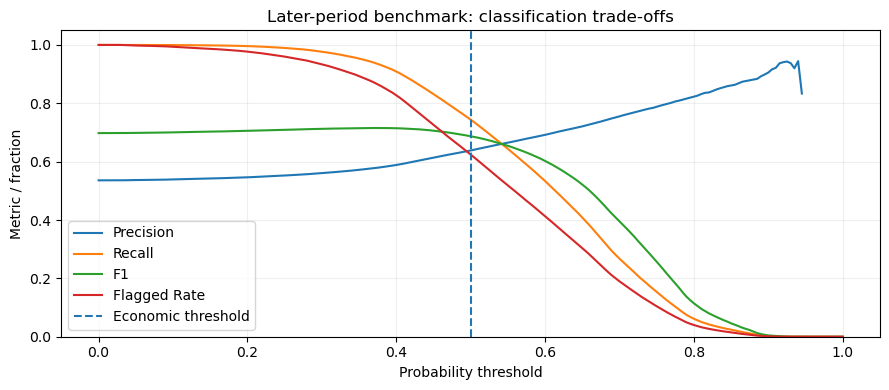

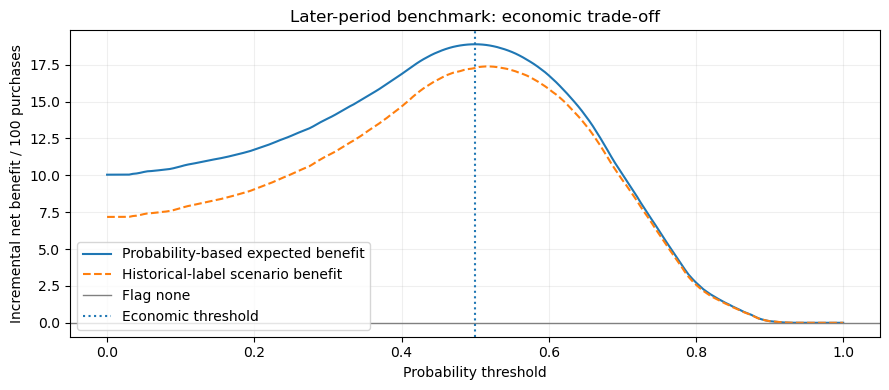

In [17]:
plot_thresholds = np.linspace(0, 1, 201)
benchmark_curve = policy_metrics(benchmark_data, plot_thresholds, *main_parameters)

fig, ax = plt.subplots(figsize=(9, 4))
for metric in ["precision", "recall", "f1", "flagged_rate"]:
    values = benchmark_curve[metric].copy()
    if metric == "precision":
        values = values.where(benchmark_curve.flagged_rate > 0)
    ax.plot(plot_thresholds, values, label=metric.replace("_", " ").title())
if 0 <= main_threshold <= 1:
    ax.axvline(main_threshold, linestyle="--", label="Economic threshold")
ax.set(xlabel="Probability threshold", ylabel="Metric / fraction", ylim=(0, 1.05),
       title="Later-period benchmark: classification trade-offs")
ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(plot_thresholds, benchmark_curve.expected_net_per_100, label="Probability-based expected benefit")
ax.plot(plot_thresholds, benchmark_curve.scenario_net_per_100, label="Historical-label scenario benefit", linestyle="--")
ax.axhline(0, color="gray", linewidth=1, label="Flag none")
if 0 <= main_threshold <= 1:
    ax.axvline(main_threshold, linestyle=":", label="Economic threshold")
ax.set(xlabel="Probability threshold", ylabel="Incremental net benefit / 100 purchases",
       title="Later-period benchmark: economic trade-off")
ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()


### 9.6 Multi-scenario sensitivity analysis
For each combination compare the economic policy against flag-all and flag-none. Report both probability-based and historical-label scenario benefit. The latter is a counterfactual calculation under a constant assumed prevention rate, not a causal estimate. The grid is a sensitivity analysis, not a search for the most favorable real-world costs.

Scenarios evaluated: 100


,return_cost,intervention_cost,efficacy,threshold,flagged_rate,precision,recall,expected_targeted,expected_all,expected_none,expected_advantage,scenario_targeted,scenario_all,expected_prevented_per_100
0,10,0.2,0.02,1.0000,0.0000,0.0000,0.0000,0.0000,-8.9958,0.0,0.0000,0.0000,-9.2822,0.0000
1,10,0.2,0.05,0.4000,0.8275,0.5886,0.9089,8.3527,7.5104,0.0,0.8423,7.8021,6.7945,2.4903
2,10,0.2,0.10,0.2000,0.9770,0.5463,0.9960,35.1800,35.0208,0.0,0.1593,33.8351,33.5890,5.4720
3,10,0.2,0.20,0.1000,0.9935,0.5391,0.9995,90.0835,90.0415,0.0,0.0420,87.2553,87.1779,10.9953
4,10,0.2,0.30,0.0667,0.9969,0.5375,0.9998,145.0811,145.0623,0.0,0.0188,140.8017,140.7669,16.5020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,40,3.0,0.02,3.7500,0.0000,0.0000,0.0000,0.0000,-255.9834,0.0,0.0000,0.0000,-257.1288,0.0000
96,40,3.0,0.05,1.5000,0.0000,0.0000,0.0000,0.0000,-189.9585,0.0,0.0000,0.0000,-192.8221,0.0000
97,40,3.0,0.10,0.7500,0.1042,0.7881,0.1533,2.0452,-79.9170,0.0,2.0452,1.5876,-85.6442,0.8329
98,40,3.0,0.20,0.3750,0.8649,0.5793,0.9349,150.5848,140.1660,0.0,10.4188,141.3441,128.7117,10.2516


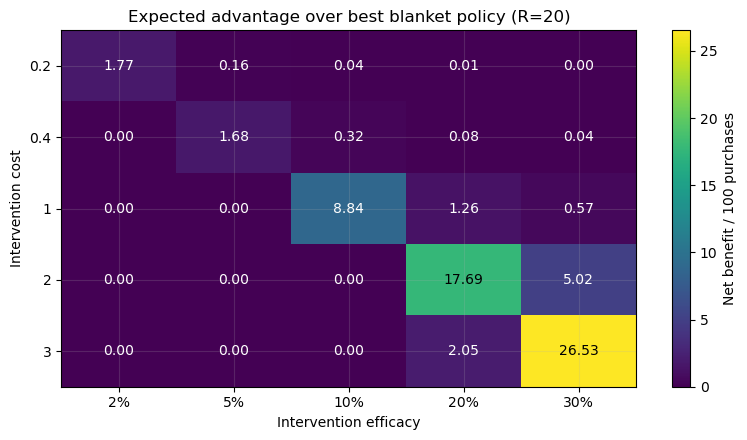

In [18]:
from itertools import product

scenario_records = []
for return_cost, intervention_cost, efficacy in product(
    RETURN_COST_GRID, INTERVENTION_COST_GRID, EFFICACY_GRID
):
    threshold = economic_threshold(return_cost, intervention_cost, efficacy)
    comparison = policy_metrics(benchmark_data, [threshold, -np.inf, np.inf],
                                return_cost, intervention_cost, efficacy)
    targeted, all_orders, no_orders = [comparison.iloc[i] for i in range(3)]
    scenario_records.append({
        "return_cost": return_cost, "intervention_cost": intervention_cost,
        "efficacy": efficacy, "threshold": threshold,
        "flagged_rate": targeted.flagged_rate, "precision": targeted.precision,
        "recall": targeted.recall,
        "expected_targeted": targeted.expected_net_per_100,
        "expected_all": all_orders.expected_net_per_100,
        "expected_none": no_orders.expected_net_per_100,
        "expected_advantage": targeted.expected_net_per_100 - max(0, all_orders.expected_net_per_100),
        "scenario_targeted": targeted.scenario_net_per_100,
        "scenario_all": all_orders.scenario_net_per_100,
        "expected_prevented_per_100": targeted.expected_prevented_per_100,
    })
scenario_grid = pd.DataFrame(scenario_records)
# A mathematical check: under the stated assumptions the economic rule
# cannot have lower probability-based expected benefit than all or none.
assert (scenario_grid.expected_advantage >= -1e-8).all()
print(f"Scenarios evaluated: {len(scenario_grid)}")
display(scenario_grid.round(4))

# Heatmap slice: choose any return cost present in RETURN_COST_GRID.
HEATMAP_RETURN_COST = min(RETURN_COST_GRID, key=lambda x: abs(x - RETURN_COST_MAIN))
heatmap = scenario_grid[scenario_grid.return_cost == HEATMAP_RETURN_COST].pivot(
    index="intervention_cost", columns="efficacy", values="expected_advantage")
fig, ax = plt.subplots(figsize=(8, 4.5))
image = ax.imshow(heatmap.to_numpy(), aspect="auto", cmap="viridis")
ax.set_xticks(range(len(heatmap.columns)), [f"{e:.0%}" for e in heatmap.columns])
ax.set_yticks(range(len(heatmap.index)), [f"{c:g}" for c in heatmap.index])
for i in range(len(heatmap.index)):
    for j in range(len(heatmap.columns)):
        value = heatmap.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                color="white" if image.norm(value) < .5 else "black")
ax.set(xlabel="Intervention efficacy", ylabel="Intervention cost",
       title=f"Expected advantage over best blanket policy (R={HEATMAP_RETURN_COST:g})")
fig.colorbar(image, ax=ax, label="Net benefit / 100 purchases")
plt.tight_layout(); plt.show()


### 9.7 Optional interactive scenario explorer
Use sliders in Jupyter to change the three assumptions without training again. If widgets are unavailable, edit Section 9.2 and rerun instead.

In [19]:
def show_business_scenario(return_cost=20., intervention_cost=1., efficacy=0.10):
    threshold = economic_threshold(return_cost, intervention_cost, efficacy)
    summary = policy_metrics(benchmark_data, [threshold, -np.inf, np.inf],
                             return_cost, intervention_cost, efficacy)
    summary.insert(0, "policy", ["Economic rule", "Flag all", "Flag none"])
    print(f"Break-even threshold: {threshold:.2%}" if np.isfinite(threshold) else "No effective intervention")
    display(summary.round(4))

try:
    import ipywidgets as widgets
    widgets.interact_manual(
        show_business_scenario,
        return_cost=widgets.FloatSlider(value=20, min=0, max=100, step=1, description="Return cost"),
        intervention_cost=widgets.FloatSlider(value=1, min=0, max=10, step=.1, description="Action cost"),
        efficacy=widgets.FloatSlider(value=.10, min=0, max=1, step=.01, description="Efficacy"),
    )
except ImportError:
    print("Optional: install ipywidgets, or call show_business_scenario(20, 1, .10).")


interactive(children=(FloatSlider(value=20.0, description='Return cost', step=1.0), FloatSlider(value=1.0, des…

### 9.8 Interpretation and deployment limitations
- If interventions are inexpensive and effective, flag-all may be nearly as good as targeted intervention. If costs are high or efficacy low, flag-none may be preferable. The incremental value of targeting is its advantage over the better blanket strategy.
- The probability-based economic policy is optimal *by construction* under the stated assumptions; that comparison alone does not establish realized savings. The historical-label scenario provides a separate descriptive check but also assumes an unmeasured treatment effect.
- Report the economic threshold, flagged rate, precision, recall, expected prevented returns, expected net benefit and the historical-label scenario benefit. Precision is displayed as zero when no purchases are flagged (mathematically undefined).
- The cohort includes customers with a return history and may not represent all shoppers. Recalibrate on a representative population and measure actual incremental efficacy, costs and customer friction through randomized A/B testing. Check capacity constraints and subgroup impacts before deployment.
- The displayed results depend on the upstream fitted models and calibrated prediction arrays. Max precision may flag very few purchases; inspect flagged_count and true_positives rather than relying on rounded rates.

## 10. Takeaways and next steps
Read the generated CV comparison and later-period benchmark before claiming improvement. Prefer a simpler model if gains are small, and verify probability quality and subgroup behavior. A third mature period with actual checkout price and time-stamped history is the highest-priority next dataset. Validate intervention efficacy through an A/B test.


**Reproducibility:** Restart the kernel and run all cells in order on the six source files. The displayed economic results are illustrative scenario estimates, not observed intervention savings.